In [1]:
import duckdb
import pandas as pd
import pyarrow as py
import matplotlib.pyplot as plt
from scipy import stats

con = duckdb.connect()

### Tableau des règles métiers :

| colonne | règle |
|---|---|
| `hors_0_100` | un nutriment en g/100 g (lipides, saturés, glucides, sucres, fibres, protéines, sel) négatif ou > 100 |
| `energie_hors_0_900` | énergie < 0 ou > 900 kcal/100 g |
| `energie_incoherente` | écart relatif > 50 % entre l'énergie déclarée et 4 × glucides + 4 × protéines + 9 × lipides, quand ce calcul vaut au moins 50 kcal |
| `energie_nulle_macros` | énergie = 0 avec au moins un macronutriment > 0 |
| `sucres_sup_glucides` | sucres > glucides + 0,5 |
| `satures_sup_lipides` | saturés > lipides + 0,5 |
| `sel_sodium` | \|sel − 2,5 × sodium\| > 0,1 |
| `product_name` | sortir les product_name qui ont une longueur de 1 |
| `code` | Dégagé tout code qui est en dessous des 8 caractères, aussi dégagé tout code qui est en doublon viré uniquement le moins remplis |

### Tableau des stratégies de valeurs manquantes par colonne et par usage :

| colonne | usage | manquants | décision | pourquoi |
|---|---|---|---|---|
| allergens | affichage, assistant | 72 % | NULL, ou chaîne vide sans ingrédients → NA + drapeau allergens_missing ; chaîne vide avec ingrédients → « aucun allergène déclaré » ; jamais imputer | sans ingrédients, l’absence d’allergène ne peut pas être affirmée (manque quasi identique à ingredients_text) ; un allergène inventé ou omis est un risque pour l’utilisateur, l’assistant répond « information non disponible » |
| brands | affichage, substitution (même marque), assistant | 34 % | garder NA + drapeau ; « unknown » à l'affichage seulement | aucune valeur plausible à inventer |
| product_name | affichage, assistant | 6 % | garder NA + drapeau product_name_missing ; « nom non renseigné » à l’affichage seulement ; jamais imputer | aucun nom plausible à inventer ; sans nom, le produit reste utilisable pour le score et la substitution ; seul le premier nom de la liste (première langue) est conservé |
| categories_tags | substitution, features ML (food_groups_tag_1), assistant | 56 % | règle métier : inclassable si vide (NULL ou liste vide) et food_groups_tag_1 NULL → drapeau unclassifiable, exclu de la substitution, ligne conservée ; jamais imputée | sans catégorie ni groupe alimentaire, impossible de comparer un produit à un « même rayon » ; la ligne reste utile pour le Nutri-Score, l’affichage et l’assistant, donc pas de suppression |
| completness | analyse interne (justification du MAR), features ML | 0 % | garder telle quelle, non exposée dans l’application | mesure le remplissage de la fiche, partiellement redondante avec les drapeaux _missing ; valeurs jusqu’à 1,1 (0,36 % > 1), conservées car elles ne sont pas aberrantes |
| ingredients_text | assistant, features texte | 72 % | garder NA + drapeau | aucune valeur plausible à inventer |
| nova_group | affichage | 75 % | garder NA + drapeau | dérivée des ingrédients, si ingredient absent = 98.5% de chance que nova absent aussi |
| nutriscore_score/_grade | cible du modèle, affichage | 34 % | garder ; « unknown » → NA ; jamais imputer | une cible imputée est une cible inventée |
| energy_kcal_100g | score, affichage, features ML, substitution, assistant | 28 % | imputation métier : kJ / 4,184, sinon 4/4/9 ; reste → médiane par food_groups_tag_1 calculée sur le train uniquement, après le split + drapeau | dérivable avant d'être devinée, attention ici le energy_kcal_100g_missing veut dire manquante après dérivation 4/4/9, médiane sur les NA sera appliqué dans le pipelline ML |
| sugars_100g | score, features ML, affichage, assistant | 32 % | garder NA + drapeau sugars_missing, jamais imputer | une valeur inventée fausserait le score, manque MAR lié à la complétude de la fiche et au catégorie de nourriture |
| salt_100g / sodium_100g | score, features ML, substitution, affichage, assistant | 37 % | imputation métier : sel = sodium × 2,5 (et inverse) | relation exacte, zéro risque |
| fiber_100g | score, features ML, substitution, affichage, assistant | 62 % | garder NA + drapeau fiber_missing + jamais imputer | MNAR : absence = souvent « pas de fibres », pas d'invention de valeur pour une composante du nutriscore |
| fruits_vegetables_legumes_100g | score, features ML, subsitution, affichage, assistant | 83 % | NA + drapeau, jamais imputer, affichage"non renseigné" | a limité aux food_groups_tag_1 si elle est indiqué |
| serving_size | sel par portion (affichage) | 68 % | a garder, jamais imputé, affichage des valeurs pour 100g si NA | la portion est propre à chaque produit, utile quand présente, jamais imputée |
| fat_100g | features ML, contrôle de cohérence, substitution, affichage, assistant | 28 % | garder NA + drapeau fat_missing ; reste → médiane par food_groups_tag_1 calculée sur le train uniquement, après le split dans le pipeline ML | MAR : suit la complétude du tableau nutritionnel ; sert de borne haute pour les saturées, reconstitution testée, regle métier atwater testé : reconstitution du fat si 3 applicable à 0,16 % des lignes seulement, gain négligeable pour une approximation, on drop |
| proteins_100g | score, features ML, affichage, substitution, assistant | 28 % | garder NA + drapeau proteins_missing ; reste → médiane par food_groups_tag_1 calculée sur le train uniquement, après le split dans le pipeline ML | MAR : manque groupé composante favorable du Nutri-Score |
| carbohydrates_100g | features ML, contrôle de cohérence, substitution, affichage, assistant | 28 % | garder NA + drapeau carbohydrates_missing ; valeurs > 100 → NA ; sert de borne haute pour sugars_100g ; jamais imputée | utile au profil nutritionnel ; une valeur inventée fausserait les contrôles de cohérence |
| saturated_fat_100g | score, features ML, affichage, substitution, assistant | 34 % | garder NA + drapeau saturated_fat_missing, règle métier : si fat_100g < 0,5 g → saturées = 0 ; sinon jamais imputer ; score non calculable si NA | composante directe du Nutri-Score, une valeur inventée fausserait le score |
| produit sans aucun nutriment clé | — | 27 % | supprimer la ligne | inutilisable pour le score et la substitution |

| # | Règle | Source | Type | Traitement | Méthode / emplacement | Statut |
|---|---|---|---|---|---|---|
| 1 | `hors_0_100` : nutriment négatif ou > 100 g/100 g | tableau règle métier | Règle métier (qualité) | NA (+ drapeau selon la colonne) | `neutralize_range` / `RANGES` | Respectée (sodium borné à 40, fruits/légumes aussi) |
| 2 | `energie_hors_0_900` : énergie < 0 ou > 900 kcal | tableau règle métier | Règle métier (qualité) | NA, puis reconstruction par `impute_energy_business` | `RANGES` (kcal 0-900, kJ 0-3 765,6) | Respectée |
| 3 | `energie_incoherente` : écart relatif > 50 % avec 4 × glucides + 4 × protéines + 9 × lipides (calcul ≥ 50 kcal) | tableau règle métier | Règle métier (qualité) | recalcul 4/4/9 de l'énergie (exception : boissons alcoolisées), kJ réalignés (kcal × 4,184) | `correct_energy` (à créer, après `RANGES`, avant `impute_energy_business`) | À implémenter |
| 4 | `energie_nulle_macros` : énergie = 0 avec au moins un macronutriment > 0 | tableau règle métier | Règle métier (qualité) | recalcul 4/4/9 de l'énergie (exception : boissons alcoolisées), kJ réalignés | `correct_energy` (à créer) | À implémenter |
| 5 | `sucres_sup_glucides` : sucres > glucides + 0,5 | tableau règle métier | Règle métier (qualité) | sucres → NA + drapeau | `neutralize_sugars` | À corriger (ajouter la tolérance de 0,5) |
| 6 | `satures_sup_lipides` : saturées > lipides + 0,5 | tableau règle métier | Règle métier (qualité) | saturées → NA + drapeau | `apply_saturated_fat_rule` | À corriger (ajouter la tolérance de 0,5) |
| 7 | `sel_sodium` : abs(sel − 2,5 × sodium) > 0,1 | tableau règle métier | Règle métier (qualité) | sodium recalculé depuis le sel (sodium = sel / 2,5) | `impute_salt_sodium` (à modifier, nouveau cas : les deux valeurs présentes) | À implémenter |
| 8 | Saturées = 0 si `fat_100g` < 0,5 (NA d'origine uniquement) | tableau strat manquante | Règle métier (déduction exacte) | valeur 0 | `apply_saturated_fat_rule` | Respectée |
| 9 | Énergie : kJ / 4,184, puis 4/4/9 (valeurs manquantes) | tableau strat manquante | Règle métier (dérivation) | dérivation | `impute_energy_business` | Respectée |
| 10 | Sel = sodium × 2,5 et inverse (quand l'un manque) | tableau strat manquante | Règle métier (relation exacte) | dérivation exacte | `impute_salt_sodium` | Respectée |
| 11 | Médiane par groupe alimentaire sur le train (énergie, fat, protéines) | tableau strat manquante | Stratégie de valeurs manquantes (imputation statistique) | imputation après le split | `median_by_aisle_after_split` | Respectée |
| 12 | Suppression des lignes sans composante du score | tableau strat manquante | Stratégie de valeurs manquantes (suppression) | suppression | `drop_rows_without_key_nutrient` | Respectée (liste stricte) |
| 13 | Inclassable : catégories vides et `food_groups_tag_1` NULL | tableau strat manquante | Règle métier (besoin de la substitution) | drapeau `unclassifiable`, ligne conservée | `flag_unclassifiable` | Respectée |
| 14 | `unknown` / `not-applicable` du grade → NA | tableau strat manquante | Stratégie de valeurs manquantes (recodage de manquants déguisés) | NA + drapeau `grade_not_applicable` | `normalize_grade` | Respectée |
| 15 | Garder NA + drapeau, jamais imputer (sucres, saturées, glucides, fibres, fruits/légumes, marques, ingrédients, nova, nom) | tableau strat manquante | Stratégie de valeurs manquantes | drapeau `_missing` | `neutralize_range`, `flag_missing`, méthodes dédiées | Respectée |
| 16 | Allergènes : NULL ou vide sans ingrédients → NA + drapeau | tableau strat manquante | Les deux (règle métier d'interprétation du vide, puis stratégie) | NA + drapeau | `flag_allergens` | Respectée |
| 17 | Reconstitution du fat par (énergie − 4P − 4G) / 9 | tableau strat manquante | Règle métier (abandonnée) | aucun | aucune | Abandonnée (0,16 % des lignes) |

In [2]:
con.sql("""
    CREATE TABLE products_nutrition AS
    SELECT
        t.code,
        t.product_name[1].text AS product_name,
        NULLIF(t.brands, '') AS brands,
        t.categories_tags,
        t.compared_to_category AS main_category,
        t.food_groups_tags[1] AS food_groups_tag_1,
        t.food_groups_tags[2] AS food_groups_tag_2,
        array_to_string(t.allergens_tags, ',') AS allergens,
        t.ingredients_text[1].text AS ingredients_text,
        t.nova_group,
        t.nutriscore_score,
        t.nutriscore_grade,
        t.serving_size,
        t.completeness,
        list_filter(t.nutriments, x -> x.name = 'energy-kcal')[1]."100g" AS energy_kcal_100g,
        COALESCE(
            list_filter(t.nutriments, x -> x.name = 'energy-kj')[1]."100g",
            list_filter(t.nutriments, x -> x.name = 'energy')[1]."100g"
        ) AS energy_kj_100g,
        list_filter(t.nutriments, x -> x.name = 'fat')[1]."100g" AS fat_100g,
        list_filter(t.nutriments, x -> x.name = 'saturated-fat')[1]."100g" AS saturated_fat_100g,
        list_filter(t.nutriments, x -> x.name = 'carbohydrates')[1]."100g" AS carbohydrates_100g,
        list_filter(t.nutriments, x -> x.name = 'sugars')[1]."100g" AS sugars_100g,
        list_filter(t.nutriments, x -> x.name = 'fiber')[1]."100g" AS fiber_100g,
        list_filter(t.nutriments, x -> x.name = 'proteins')[1]."100g" AS proteins_100g,
        list_filter(t.nutriments, x -> x.name = 'salt')[1]."100g" AS salt_100g,
        list_filter(t.nutriments, x -> x.name = 'sodium')[1]."100g" AS sodium_100g,
        list_filter(t.nutriments, x -> x.name = 'fruits-vegetables-legumes')[1]."100g" AS fruits_vegetables_legumes_100g
    FROM '../../data/food.parquet' AS t
""")

### Tableau du nombres de valeurs et leur IQR/Z/Zrobust : 

In [5]:
SHELVES = [
    "en:sugary-snacks", "en:fish-meat-eggs", "en:cereals-and-potatoes",
    "en:milk-and-dairy-products", "en:beverages", "en:fats-and-sauces",
    "en:fruits-and-vegetables", "en:composite-foods", "en:salty-snacks",
]
KEY_NUTRIENTS = [
    "energy_kcal_100g", "saturated_fat_100g", "sugars_100g",
    "fiber_100g", "proteins_100g", "salt_100g",
]

def load_shelves_data(con, shelves=SHELVES):
    """Charge dans pandas les produits des rayons retenus, avec uniquement les colonnes utiles."""
    return con.execute("""
        SELECT
            code,
            product_name,
            food_groups_tag_1,
            energy_kcal_100g,
            fat_100g,
            saturated_fat_100g,
            carbohydrates_100g,
            sugars_100g,
            fiber_100g,
            proteins_100g,
            salt_100g,
            sodium_100g
        FROM products_nutrition
        -- On ne garde que les lignes dont le rayon est dans la liste fournie
        WHERE list_contains(?, food_groups_tag_1)
    """, [shelves]).df()


df = load_shelves_data(con)


def statistical_outliers(s: pd.Series) -> pd.DataFrame:
    """Retourne trois colonnes booléennes (iqr, z, z_robust) et indique si la MAD est nulle."""
    # float64 pour éviter les écarts d'arrondi de float32
    s = s.astype("float64")

    # Les NA sont ignorés automatiquement par quantile, mean, std et median
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mad = stats.median_abs_deviation(s.dropna(), scale="normal")

    result = pd.DataFrame(index=s.index)
    # IQR : hors de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR]
    result["iqr"] = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    # Z-score : écart à la moyenne supérieur à 3 écarts-types
    result["z"] = ((s - s.mean()) / s.std()).abs() > 3
    # Z-score robuste : si MAD nulle, la division est impossible, on ne signale rien
    if mad == 0:
        result["z_robust"] = False
    else:
        result["z_robust"] = ((s - s.median()) / mad).abs() > 3.5

    # Un NA donne False : un produit sans valeur n'est jamais signalé
    result = result.fillna(False).astype(bool)
    result.attrs["mad_is_zero"] = bool(mad == 0)
    return result

def count_outliers(df: pd.DataFrame, shelves=SHELVES, nutrients=KEY_NUTRIENTS) -> pd.DataFrame:
    """Retourne le % de produits signalés : une ligne par rayon et nutriment, une colonne par méthode."""
    rows = []
    for shelf in shelves:
        sub = df[df["food_groups_tag_1"] == shelf]
        for nutrient in nutrients:
            values = sub[nutrient]
            outliers = statistical_outliers(values)
            valid = int(values.notna().sum())

            row = {"shelf": shelf, "nutrient": nutrient, "valid": valid}
            # Une colonne par méthode : % de produits signalés parmi les valeurs renseignées
            for method in ["iqr", "z", "z_robust"]:
                row[method] = round(100 * int(outliers[method].sum()) / valid, 2) if valid else None
            row["mad_is_zero"] = outliers.attrs["mad_is_zero"]
            rows.append(row)
    return pd.DataFrame(rows)

counts = count_outliers(df)
print(counts.shape)  # attendu : (54, 7)
for nutrient in KEY_NUTRIENTS:
    print(counts[counts["nutrient"] == nutrient].to_string(index=False))

(54, 7)
                     shelf         nutrient  valid   iqr    z  z_robust  mad_is_zero
          en:sugary-snacks energy_kcal_100g 256467  2.47 0.09      0.75        False
         en:fish-meat-eggs energy_kcal_100g 167685  2.88 0.02      1.27        False
   en:cereals-and-potatoes energy_kcal_100g 173283  5.34 0.04      1.28        False
en:milk-and-dairy-products energy_kcal_100g 159741  0.15 0.08      0.12        False
              en:beverages energy_kcal_100g 135885 12.51 0.54     11.71        False
        en:fats-and-sauces energy_kcal_100g 114088  0.05 0.05      0.06        False
  en:fruits-and-vegetables energy_kcal_100g  85324  6.58 1.30     21.73        False
        en:composite-foods energy_kcal_100g  95940  3.25 0.02      2.07        False
           en:salty-snacks energy_kcal_100g  67355  0.13 0.09      0.12        False
                     shelf           nutrient  valid   iqr    z  z_robust  mad_is_zero
          en:sugary-snacks saturated_fat_100g 248564  0

### Représentation graphique IQR/Z/Zrobust par nutriment/rayons :

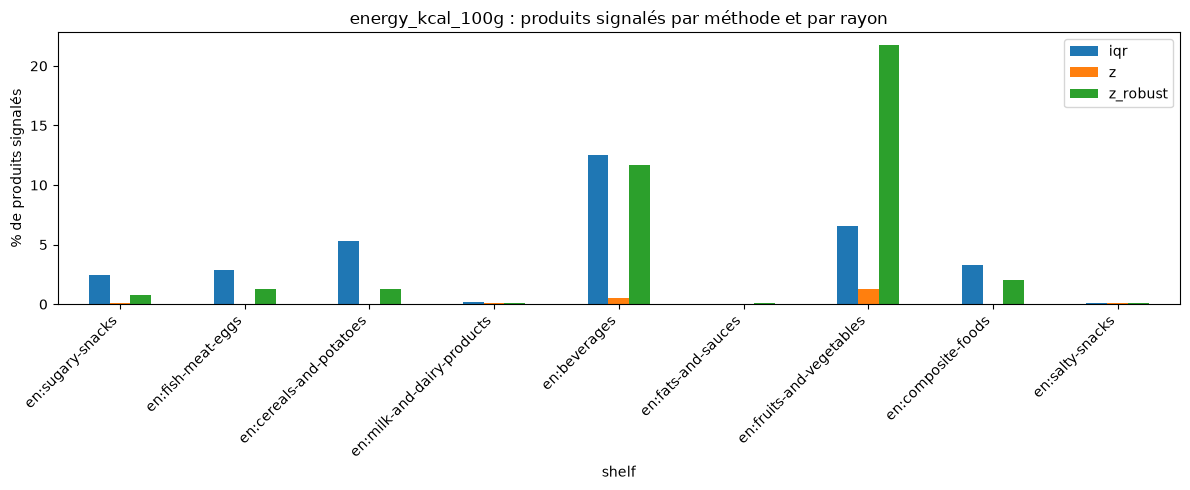

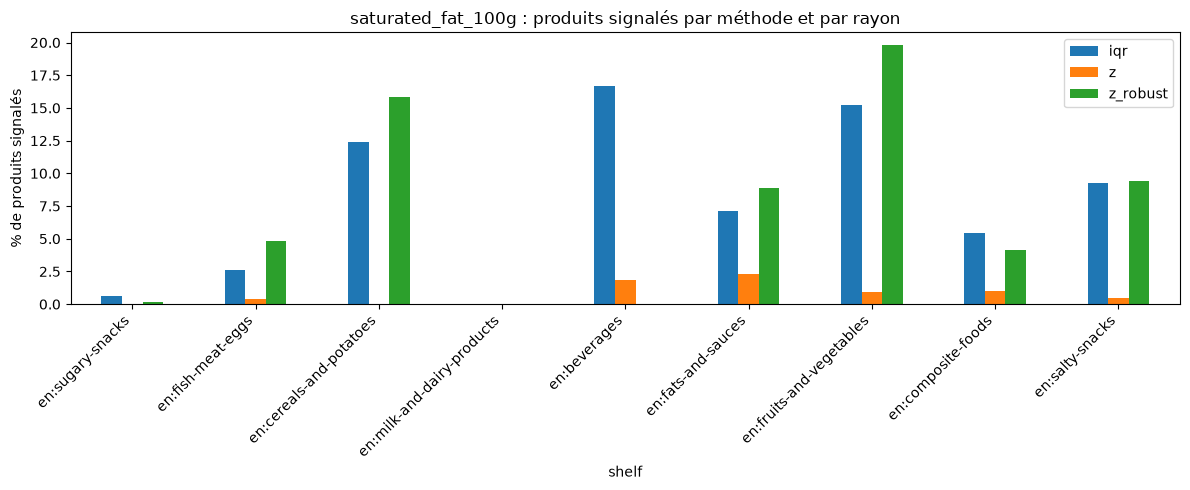

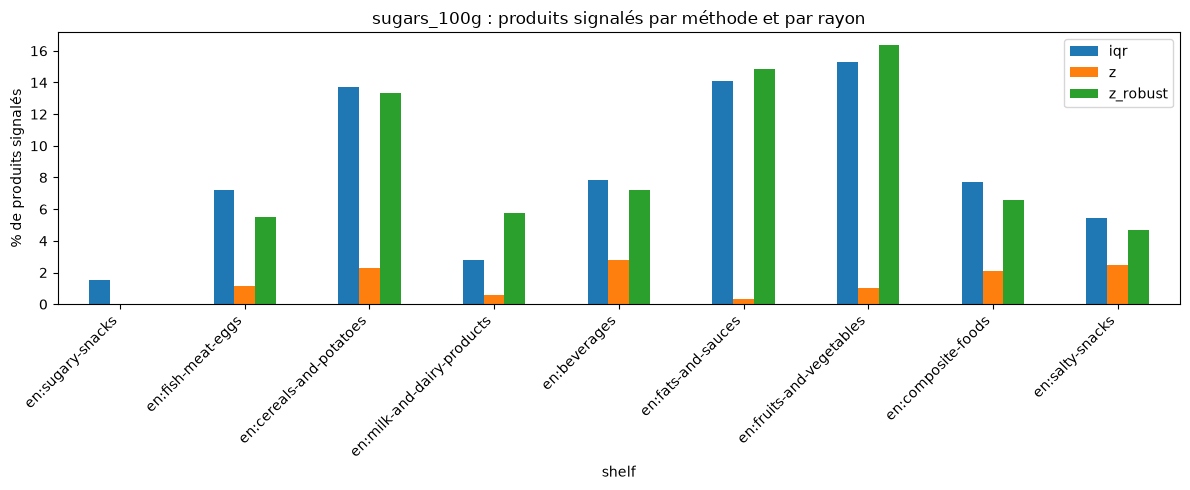

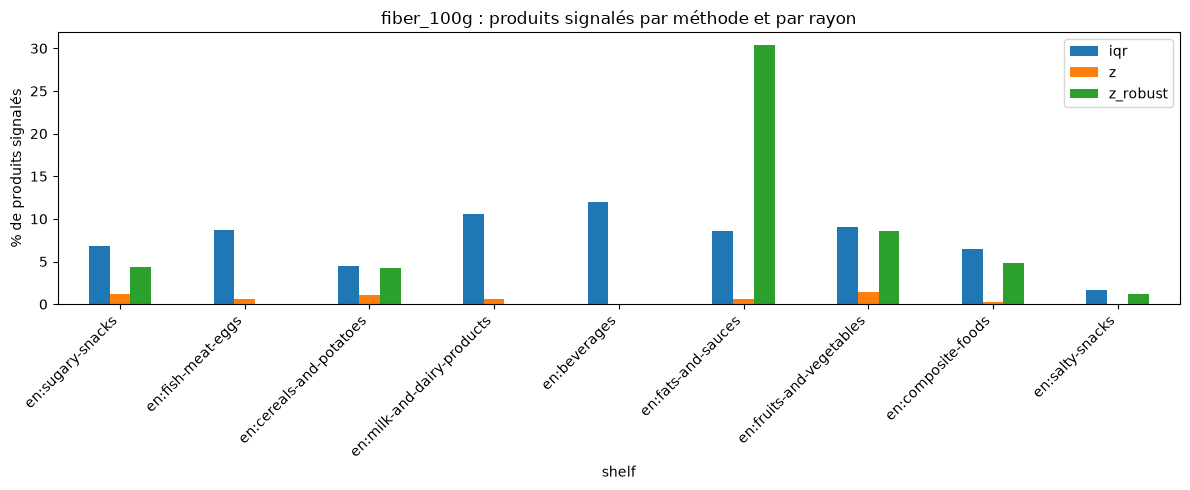

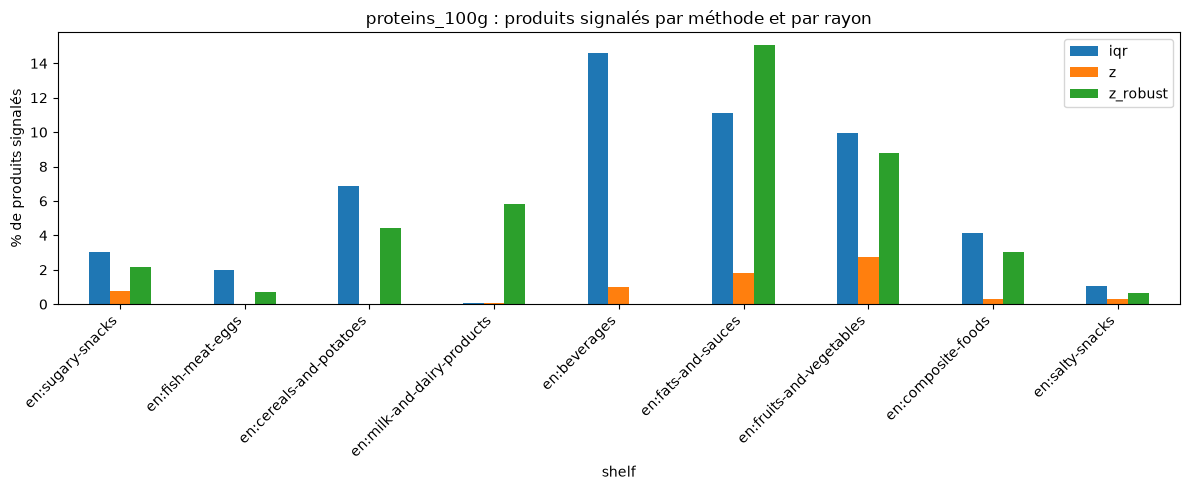

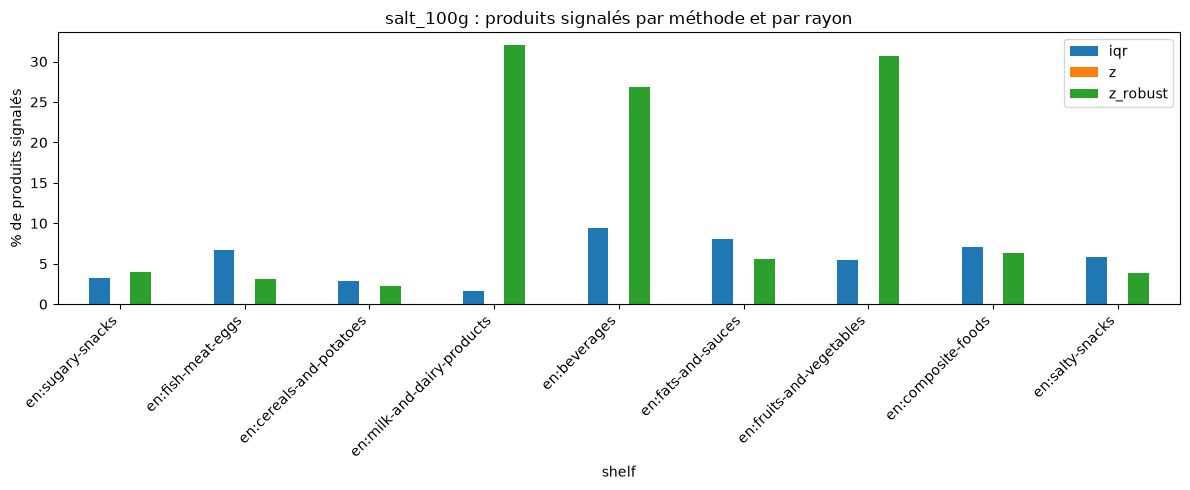

In [ ]:
def plot_flagged_bars(counts, nutrients=KEY_NUTRIENTS):
    """Barres groupées : % de produits signalés par méthode, un groupe par rayon.
    Génère un graphique par nutriment de la liste fournie."""
    axes = []
    for nutrient in nutrients:
        # Filtrage sur le nutriment courant
        table = counts[counts["nutrient"] == nutrient].set_index("shelf")[["iqr", "z", "z_robust"]]
        ax = table.plot.bar(figsize=(12, 5))
        ax.set_ylabel("% de produits signalés")
        ax.set_title(f"{nutrient} : produits signalés par méthode et par rayon")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        axes.append(ax)
    return axes

plot_flagged_bars(counts, KEY_NUTRIENTS)
plt.show()